# Retail Sales Forecasting and Customer Segmentation

**Data:** UCI *Online Retail* transactions: a UK online gift retailer selling mostly to wholesalers, 1 Dec 2010 to 9 Dec 2011, 541,909 invoice lines.

**Questions**
1. What are the seasonality, trend and anomalies in demand?
2. Can weekly demand be forecast, and does ARIMA beat a simple regression baseline on a hold-out period?
3. Can customers be segmented with RFM features and K-Means into groups that really differ?

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import data, eda, forecast, segment

## 1. Load and clean

In [2]:
data.download()
raw = data.load_raw()
sales, cancels = data.clean(raw)
print(f"raw lines: {len(raw):,} | valid sales lines: {len(sales):,} | cancellation lines: {len(cancels):,}")
print(f"sales lines with no CustomerID: {sales['CustomerID'].isna().mean():.1%}")
print(f"date range: {raw['InvoiceDate'].min().date()} to {raw['InvoiceDate'].max().date()}")

raw lines: 541,909 | valid sales lines: 519,415 | cancellation lines: 8,704
sales lines with no CustomerID: 25.3%
date range: 2010-12-01 to 2011-12-09


Cleaning rules (all in `src/data.py`):
- **Cancellations** (invoices starting with `C`) are separated out.
- **Non-product codes** (postage, bank charges, fees, manual adjustments) are dropped because they are not product demand.
- **Zero or negative price and quantity** rows are dropped.
- **Fully cancelled orders** are removed along with their cancellation. A naive clean that removes only the `C` invoice leaves the original order counting as demand: one order of 74,215 units placed and cancelled within minutes on 18 Jan 2011 would otherwise be the biggest day of the year.
- About a quarter of lines have **no CustomerID**. They still count as demand but cannot be used for customer segmentation.

## 2. Exploratory analysis

In [3]:
monthly = eda.monthly_summary(sales)
monthly.assign(revenue=lambda d: d["revenue"].round(0)).astype(int)

,revenue,units,orders,customers
InvoiceDate,,,,
2010-12-01,763116,352548,1537,882
2011-01-01,561686,299147,1065,734
2011-02-01,503825,281202,1088,756
2011-03-01,679654,372349,1432,969
2011-04-01,510598,305500,1223,848
2011-05-01,732234,390752,1657,1051
2011-06-01,728215,381618,1512,988
2011-07-01,677452,393830,1444,944
2011-08-01,719024,418388,1332,930


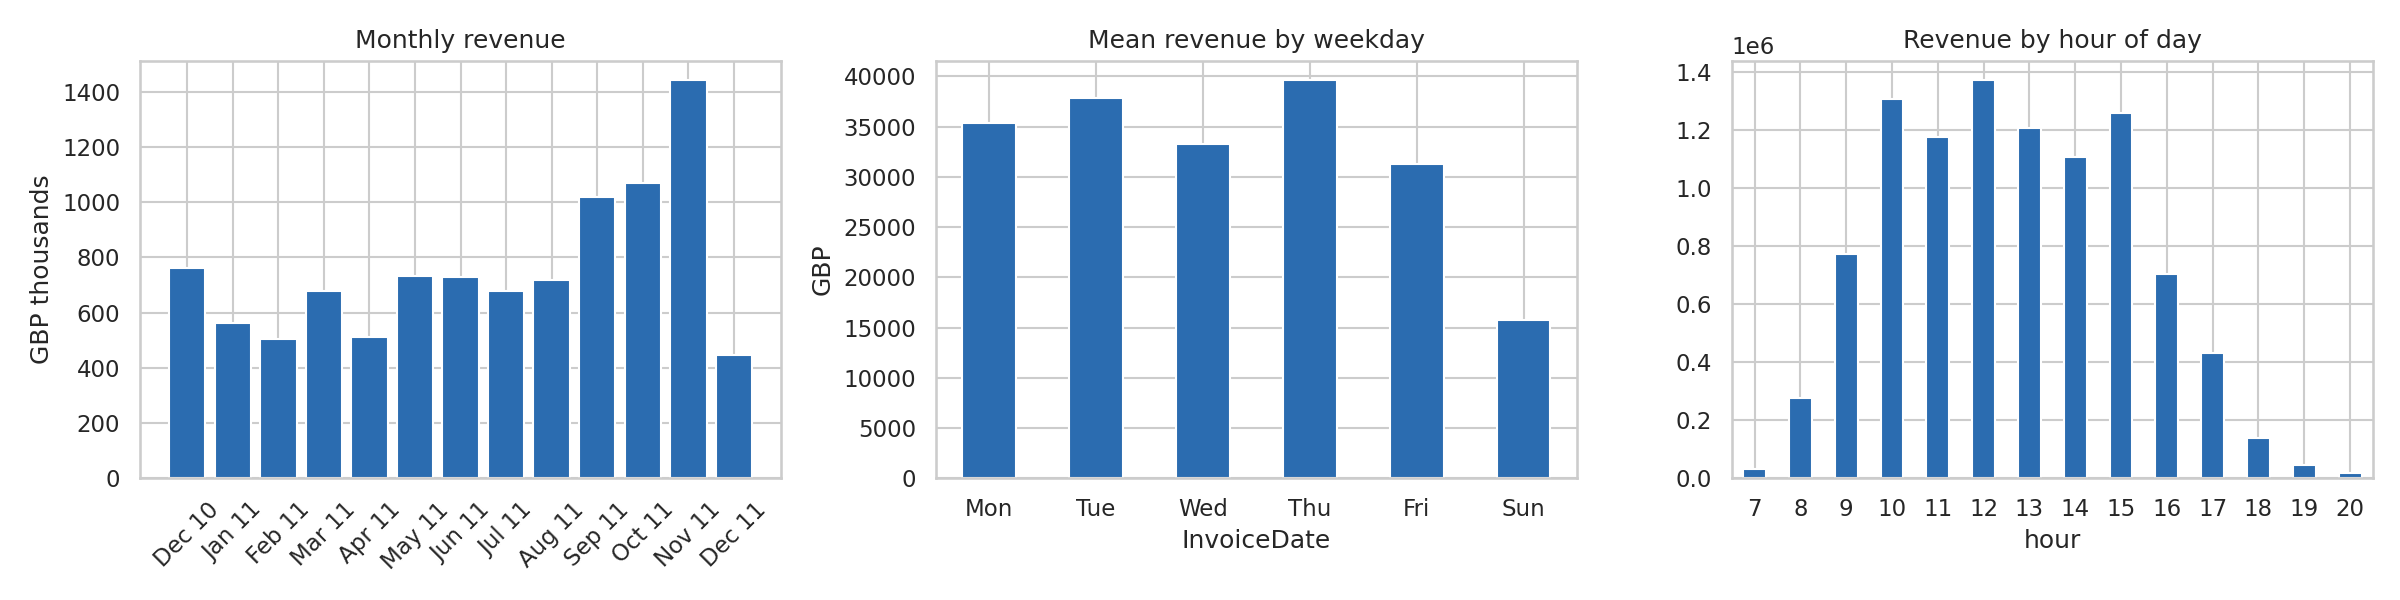

In [4]:
display(Image("reports/figures/eda_seasonality.png"))

**What the data shows**
- **Strong build-up into the autumn.** Monthly revenue stays between £0.5M and £0.73M from February to August, then climbs through September (£1.02M) and October (£1.07M) to a peak of £1.44M in November. The December 2011 figure is low only because the data stops on 9 December.
- **No Saturday trading at all** (zero transactions), and **Sunday is about half a normal weekday**. Thursday is the strongest day.
- **Sales happen between 07:00 and 20:00**, with 12:00, 10:00 and 15:00 the busiest hours.
- **Only one year of data**, so the autumn rise cannot be separated into "annual seasonality" and "growth". Both are mixed together.

In [5]:
daily = eda.daily_revenue(sales)
anom = eda.find_anomalies(daily)
print(f"{len(anom)} anomalous trading days out of {len(daily)}")
anom.round(1)

10 anomalous trading days out of 305


,revenue,local_level,robust_z
InvoiceDate,,,
2010-12-22,4825.9,29882.8,-6.7
2011-07-31,32322.3,9782.4,4.4
2010-12-23,11099.9,36329.0,-4.4
2011-02-06,3255.4,8724.4,-3.6
2011-08-11,64849.3,26069.6,3.4
2011-03-29,68660.6,28683.3,3.2
2011-07-24,26428.5,11305.8,3.1
2011-06-19,22036.2,9437.4,3.1
2011-09-11,34249.4,14784.8,3.1


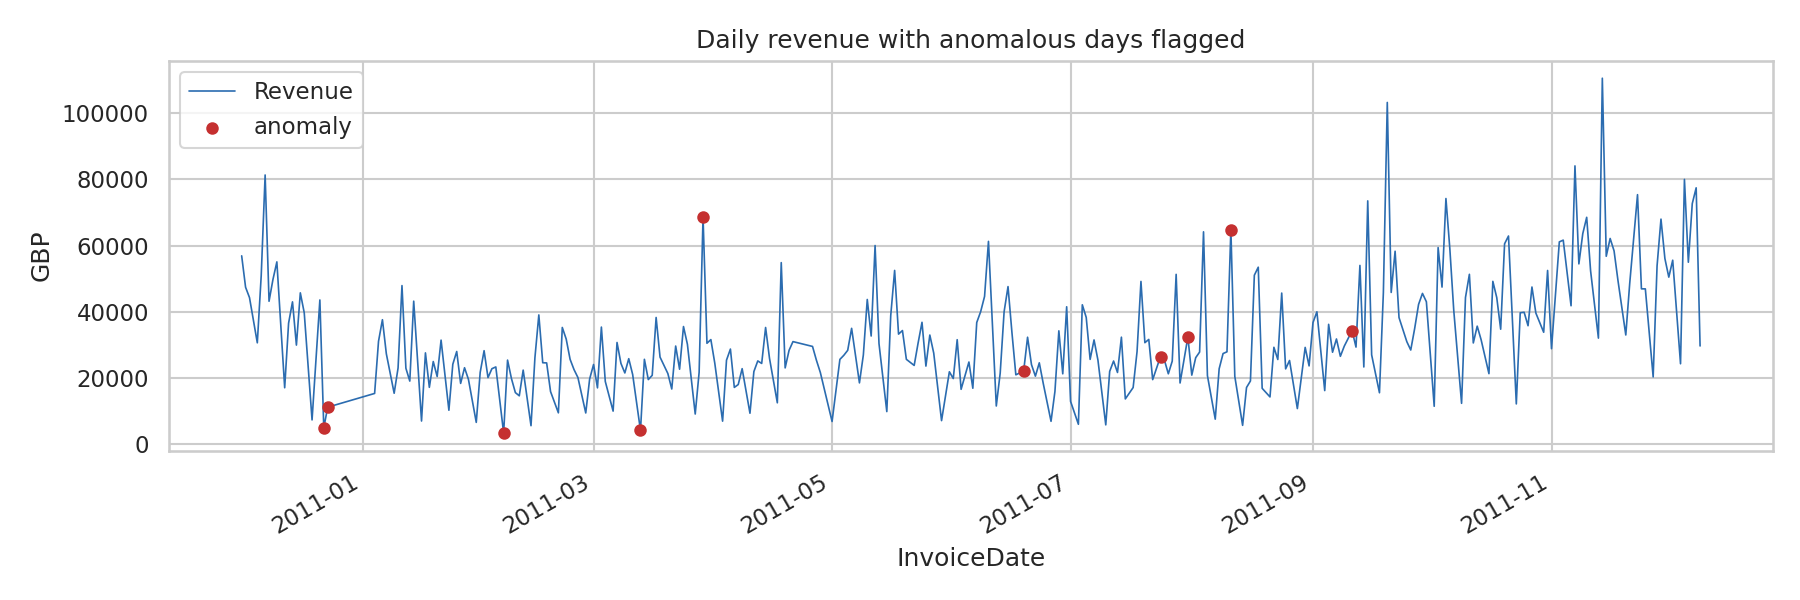

In [6]:
display(Image("reports/figures/eda_anomalies.png"))

Anomalies are days whose revenue is far from the local level after removing the normal weekday pattern (robust z-score above 3 on log revenue). The most extreme is **22 December 2010**, a very quiet day just before the shop's year-end closure (23 December is flagged too), plus a handful of isolated high days. Spikes like these are worth checking against individual large wholesale orders before using them as signals.

## 3. Forecasting weekly demand

**Target:** weekly units sold. **Series:** 47 full trading weeks, 10 Jan to 28 Nov 2011. The first weeks are excluded because the shop closes between Christmas and New Year, and the last week is incomplete.

**Validation:** walk-forward on the last 8 weeks. For each held-out week every model is fitted using only earlier weeks and predicts that one week, so nothing from the future leaks in.

**Models**
- **ARIMA**, with `d` chosen by the Augmented Dickey-Fuller test and `p`, `q` by lowest AIC on the training weeks only.
- **Regression baseline:** linear regression on last week, two weeks ago, four weeks ago, the 4-week average and a trend term.
- **Naive:** next week equals this week. Any model worth using must beat it.

In [7]:
y = data.weekly_series(sales, "Quantity")
print(len(y), "weeks:", y.index.min().date(), "to", y.index.max().date())
res = forecast.run_forecast(y)
print("ARIMA order (p, d, q):", res["order"])
res["aic_table"].head(5).round(1)

47 weeks: 2011-01-10 to 2011-11-28


ARIMA order (p, d, q): (0, 1, 1)


,p,d,q,aic
0,0,1,1,865.2
1,1,1,1,867.1
2,0,1,2,867.5
3,1,1,0,868.5
4,3,1,0,868.6


In [8]:
res["metrics"].round(1)

,model,MAE,RMSE,MAPE_%
0,ARIMA,19250.6,21055.1,12.7
1,Regression (lags + trend),18250.1,21878.0,11.3
2,Naive (last week),20134.9,25662.8,14.2


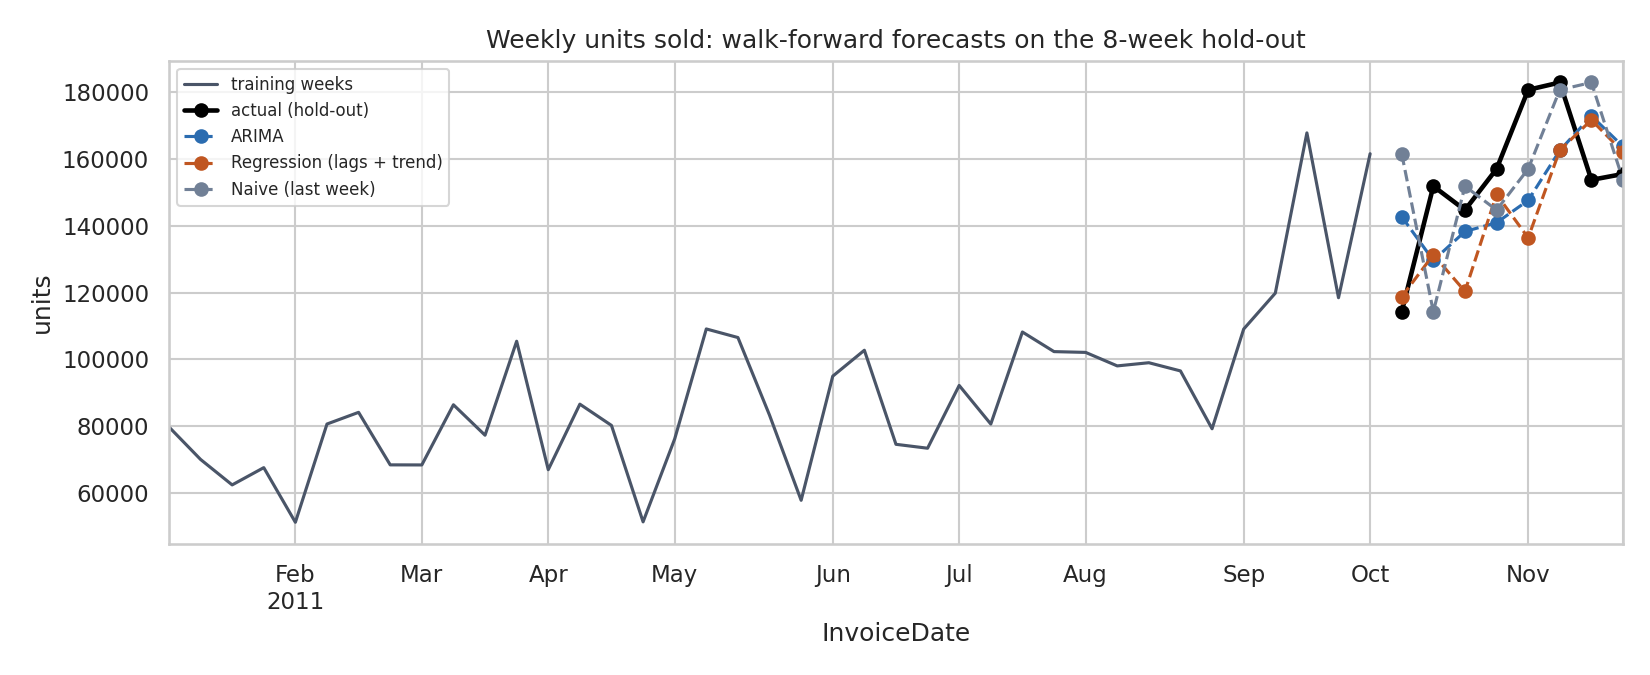

In [9]:
display(Image("reports/figures/forecast_holdout.png"))

**Reading the result**
- ARIMA(0,1,1) was selected: one difference, plus one moving-average term.
- All three approaches beat the naive baseline on every metric.
- **ARIMA has the lowest RMSE** and the **regression has the lowest MAE and MAPE**, so there is no clear winner. With only 8 held-out weeks, the gap between them is well inside what luck could produce.
- The hold-out is the hardest period of the year, the autumn ramp-up. With one year of history no model can know that November is a peak, so the models trail the rise rather than anticipate it.

**Practical conclusion:** forecast errors of roughly 11 to 13% per week are achievable, but longer-range forecasts need at least two years of data to learn seasonality properly.

## 4. Customer segmentation

**Features (RFM):** recency (days since last order), frequency (distinct invoices), monetary (total spend). They are heavily right-skewed, so they are log-transformed and standardised before K-Means.

**Customers:** only rows with a CustomerID, which is 4,322 customers.

In [10]:
rfm = segment.build_rfm(sales, cancels)
Z = segment.scale_rfm(rfm)
sil = segment.silhouette_by_k(Z)
k = segment.choose_k(sil)
print("Customers:", len(rfm), "| chosen k:", k)
sil.round(3)

Customers: 4322 | chosen k: 3


,k,silhouette,inertia
0,2,0.434,6457.232
1,3,0.340,4840.398
2,4,0.338,3931.500
3,5,0.316,3297.914
4,6,0.314,2846.386
5,7,0.309,2546.293
6,8,0.300,2331.297


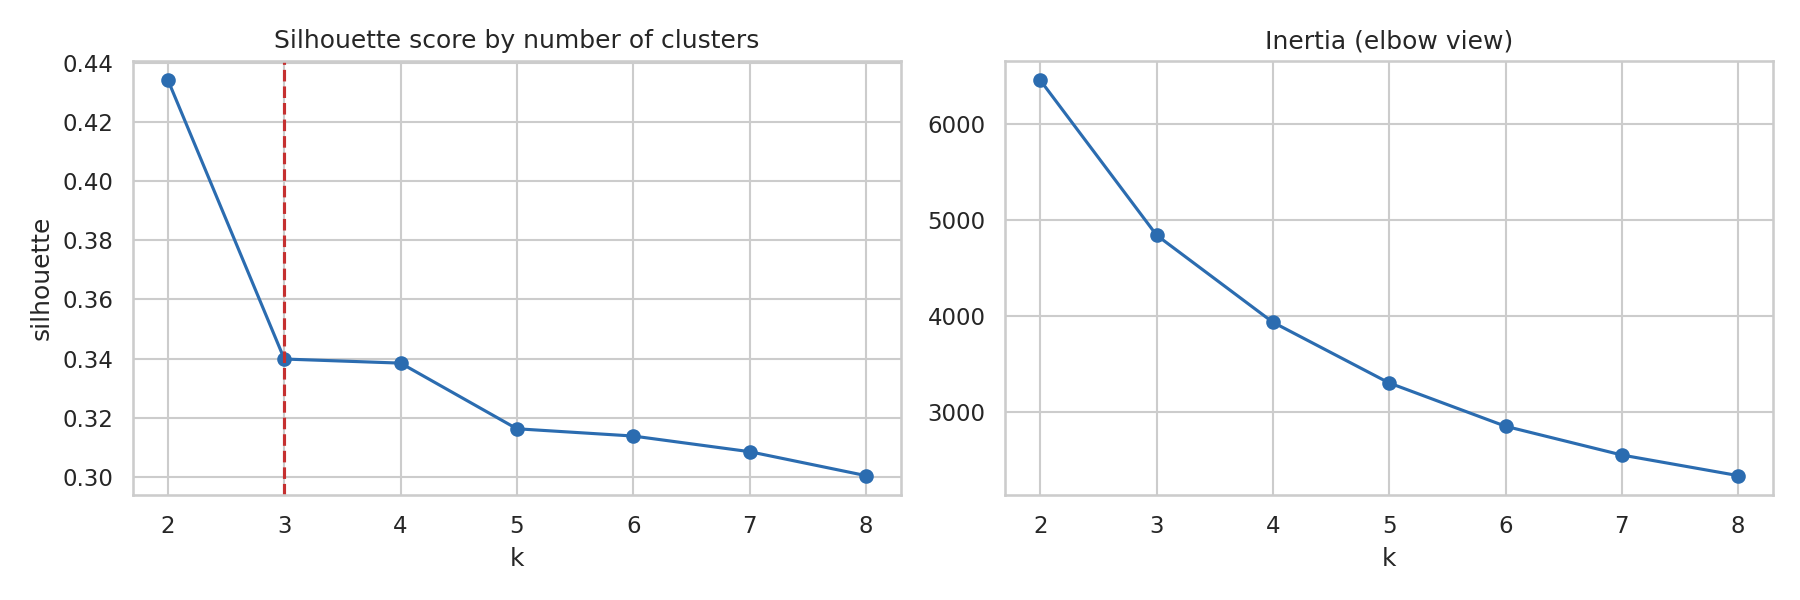

In [11]:
display(Image("reports/figures/silhouette.png", width=760))

**Choosing k.** The silhouette score is highest at **k = 2** (0.434), but that split is simply active versus lapsed customers, which is too coarse to act on. The search is therefore restricted to k of 3 or more, where **k = 3 has the best silhouette (0.340)**. Silhouette values of 0.3 to 0.4 mean the groups are real but overlap, which is normal for customer behaviour that forms a continuum rather than distinct clusters.

In [12]:
seg = segment.fit_segments(rfm, Z, k)
names = segment.label_clusters(seg)
prof = segment.profile(seg, names)
prof.set_index("segment")

,customers,mean_recency_days,mean_frequency,mean_monetary,total_revenue,median_items_per_order,mean_cancel_rate,pct_customers,pct_revenue
segment,,,,,,,,,
"High-value, recent",731,13.644,13.479,7525.155,5500888.11,215.833,0.145,16.913,65.955
"Mid-value, cooling",1685,46.275,3.490,1292.628,2178078.27,178.500,0.114,38.987,26.115
"Low-value, lapsed",1906,163.179,1.328,346.977,661338.09,126.000,0.074,44.100,7.929


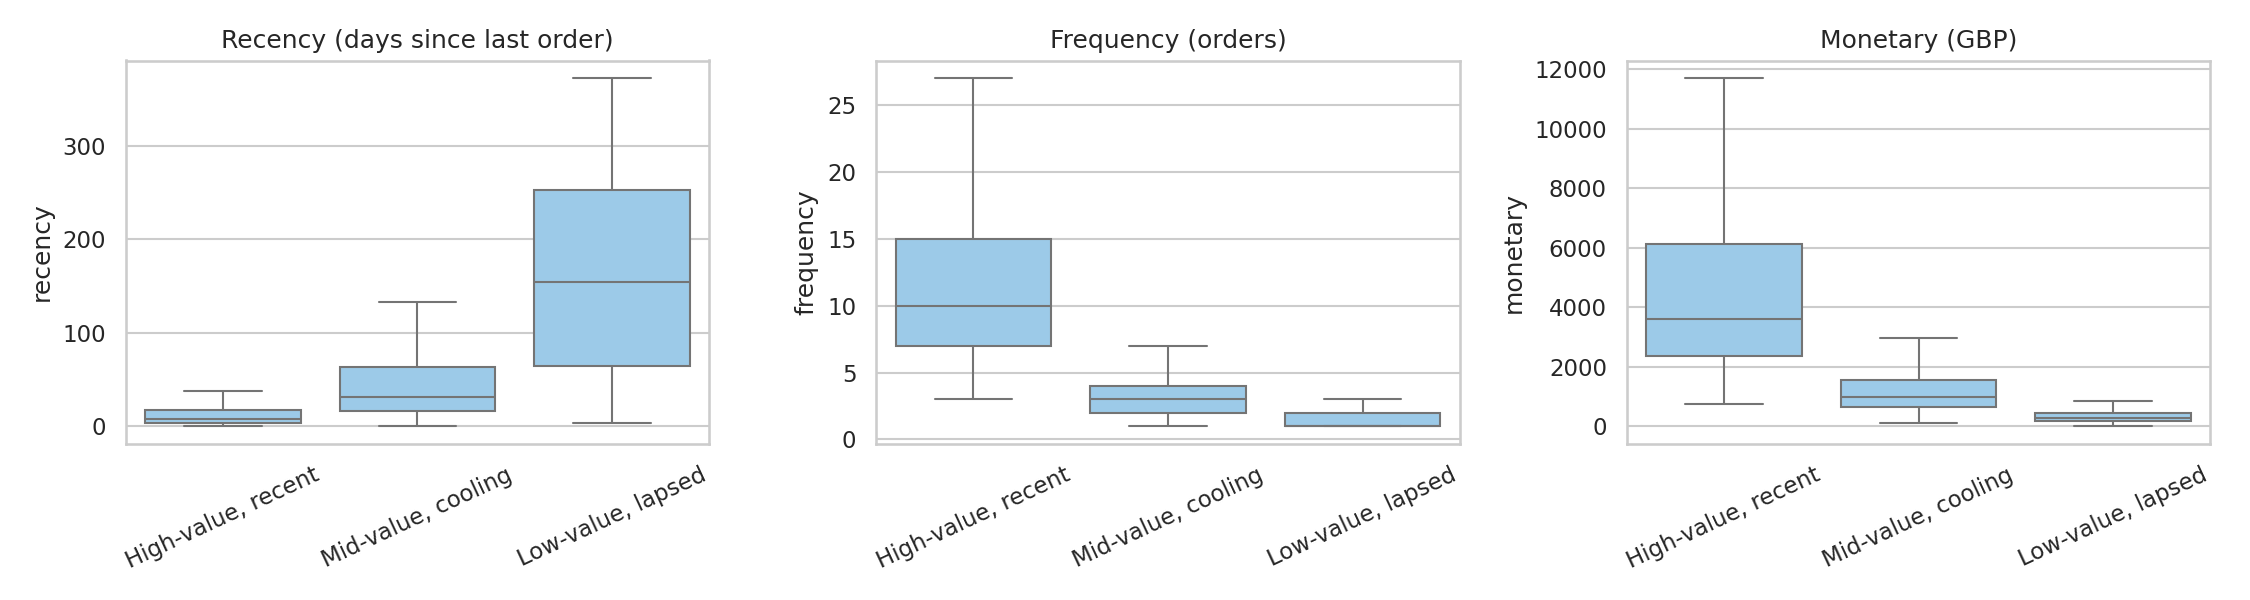

In [13]:
display(Image("reports/figures/segment_profiles.png"))

**The three segments**
- **High-value, recent:** 731 customers (17%) who order often and recently, and produce about **66% of revenue**.
- **Mid-value, cooling:** 1,685 customers (39%) with about 3 to 4 orders each, last seen around 46 days ago, producing about 26% of revenue.
- **Low-value, lapsed:** 1,906 customers (44%), mostly one or two orders, last seen about 5 to 6 months ago, producing about 8% of revenue.

The revenue concentration is the headline: protecting the top 17% matters far more than winning back the bottom 44%.

### Do the segments really differ? Hypothesis tests

Testing differences in recency, frequency or monetary would be **circular**, because the clusters were built to separate exactly those. So the tests use two behaviours **not used for clustering**: average items per order and cancellation rate.

- **Kruskal-Wallis** across the three segments, since both variables are skewed and not normal.
- **Mann-Whitney U** for each pair of segments, with Bonferroni adjustment.
- **Epsilon squared** as the effect size, so a significant result is not mistaken for an important one.

In [14]:
omni, pair = segment.test_segments(seg)
omni["p_value"] = omni["p_value"].map("{:.2e}".format)
pair["p_adjusted"] = pair["p_adjusted"].map("{:.2e}".format)
display(omni.round(4)); display(pair)

,variable,H,p_value,epsilon_squared
0,avg_items_per_order,337.7607,4.53e-74,0.0782
1,cancel_rate,447.3171,7.35e-98,0.1035


,variable,segment_a,segment_b,p_adjusted
0,avg_items_per_order,0,1,1.17e-58
1,avg_items_per_order,0,2,5.07e-43
2,avg_items_per_order,1,2,2.89e-08
3,cancel_rate,0,1,5.08e-110
4,cancel_rate,0,2,2.66e-34
5,cancel_rate,1,2,7.63e-19


**Result:** both variables differ significantly across segments (p < 0.001) and every pair of segments differs after adjustment. The effect sizes are **small to moderate** (epsilon squared about 0.08 and 0.10), so the differences are real but not dramatic. Higher-value customers place bigger orders (median about 216 items per order against 126 for the lapsed group) and also have a higher cancellation rate (14.5% against 7.4%). That second pattern is an association, not a cause: customers who order more simply have more chances to cancel.

## 5. Takeaways and limitations

**Takeaways**
- Demand builds strongly into autumn, peaking in November, and there is no Saturday trading.
- Weekly forecasts are within roughly 11 to 13% error. ARIMA and a lag regression perform about equally, and both beat the naive baseline.
- Revenue is highly concentrated: about 17% of customers produce about two thirds of revenue.

**Limitations**
- **One year of data:** seasonality and growth cannot be separated, and the hold-out covers only 8 weeks.
- **Weekly, not monthly:** a monthly forecast would have only 13 points, too few to validate, so weekly demand is forecast.
- **Quarter of lines have no CustomerID** and are absent from the segmentation.
- **K-Means silhouette is modest** (0.34), and k = 3 was chosen over the higher-scoring k = 2 for usefulness.
- The retailer sells mostly to wholesalers, so results may not carry over to consumer retail.